In [1]:
!py -m pip install scikit-learn
!py -m pip install umap-learn
!py -m pip install bioinfokit
!py -m pip install scipy
!py -m pip install PyComplexHeatmap
!py -m pip install seaborn
!py -m pip install pydeseq2
!py -m pip install gprofiler-official
!py -m pip install gseapy
!py -m pip install lxml


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
import umap
import scipy as sp
import random
import seaborn as sns
from gprofiler import GProfiler

C:\Users\Ayden\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Load the original data
df = pd.read_csv("Data/SRP064298/gene_data.tsv",sep='\t')
df

,Gene,SRR2534402,SRR2534403,SRR2534404,SRR2534405,SRR2534406,SRR2534407,SRR2534408,SRR2534409,SRR2534410,...,SRR2535038,SRR2535039,SRR2535040,SRR2535041,SRR2535042,SRR2535043,SRR2535044,SRR2535045,SRR2535046,SRR2535047
0,Gnai3,17.798948,15.751005,17.474698,17.229629,16.963489,17.299376,18.045919,16.997425,18.585447,...,18.291707,18.466178,19.431114,21.151186,20.202838,19.152004,20.567181,19.899393,19.536340,19.421168
1,Pbsn,0.236804,0.236517,0.237815,0.237395,0.234727,0.236399,0.236287,0.237697,0.231434,...,0.219176,0.219518,0.224586,0.221831,0.225496,0.222731,0.222293,0.225023,0.221662,0.225210
2,Cdc45,2.256376,2.083811,1.678759,1.801651,2.597309,2.559593,2.256376,1.677931,2.899036,...,2.566022,2.324930,2.193460,2.207419,2.722177,2.823605,2.466684,2.464955,1.512152,2.660157
3,H19,2.155539,1.777977,1.771829,1.775136,1.752313,1.781146,2.159232,2.245224,0.231434,...,1.985189,0.219518,0.224586,0.221831,1.203003,0.222731,0.222293,0.225023,1.241120,0.225210
4,Scml2,0.236804,0.236517,0.237815,1.539616,0.234727,0.236399,0.236287,0.237697,1.616331,...,0.219176,0.219518,0.224586,0.221831,0.225496,0.222731,0.222293,0.225023,0.221662,0.225210
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37766,Gm50415,0.236804,0.236517,0.237815,0.237395,0.234727,0.236399,0.236287,0.237697,0.231434,...,0.219176,0.219518,0.224586,0.221831,0.225496,0.222731,0.222293,0.225023,0.221662,0.225210
37767,Vmn1r64,0.236804,0.236517,0.237815,0.237395,0.234727,0.236399,0.236287,0.237697,0.231434,...,0.219176,0.219518,0.224586,0.221831,0.225496,0.222731,0.222293,0.225023,0.221662,0.225210
37768,Gm50102,1.649079,1.554010,1.708130,1.675913,0.234727,1.954906,2.537521,1.556532,0.231434,...,2.458047,1.768023,1.785927,0.221831,1.555982,0.222731,1.753372,1.915193,1.429358,2.111069
37769,Gm19519,0.236804,0.236517,0.237815,0.237395,0.234727,0.236399,0.236287,0.237697,0.231434,...,0.219176,0.219518,0.224586,0.221831,0.225496,0.222731,0.222293,0.225023,0.221662,0.225210


<Axes: ylabel='Density'>

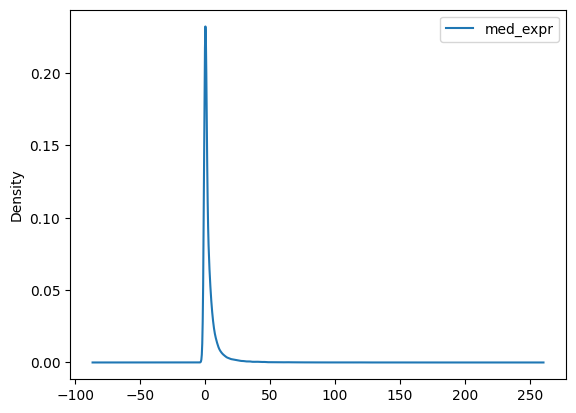

In [4]:
# Create a density plot for the per-gene median expression
d = df.drop(columns=["Gene"]).median(axis=1)
d = pd.DataFrame(data=d, columns=["med_expr"])
d["med_expr"] = d["med_expr"]
d.plot.density()

In [5]:
# Source: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

transposed_df = df.drop(columns=["Gene"]).transpose() # Transposed because 
# Scaling the data to make PCA more effective
scaled_data = StandardScaler().fit_transform(transposed_df)
pca = PCA(n_components=2)
pca.fit(scaled_data)
pca_reduction = pca.transform(scaled_data).T

Text(0.5, 1.0, 'Ad Libitum vs Restricted Feeding PCA')

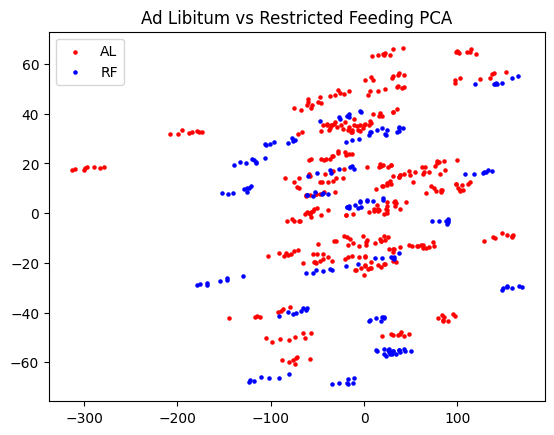

In [6]:
# WT_AL (wild type ad libitum) vs WT_RF (wild type restricted feeding)
df_meta = pd.read_csv("Data/SRP064298/metadata_SRP064298.tsv", sep="\t")

experiment_vars = list(df_meta["refinebio_title"])

WT_AL = [n.startswith("WT_AL") for n in experiment_vars]
WT_RF = [n.startswith("WT_RF") for n in experiment_vars]

plt.scatter(pca_reduction[0][WT_AL], pca_reduction[1][WT_AL], color="red", s=5, label="AL")
plt.scatter(pca_reduction[0][WT_RF], pca_reduction[1][WT_RF], color="blue", s=5, label="RF")
plt.legend()
plt.title("Ad Libitum vs Restricted Feeding PCA")

Text(0.5, 1.0, 'Ad Libitum vs Restricted Feeding TSNE')

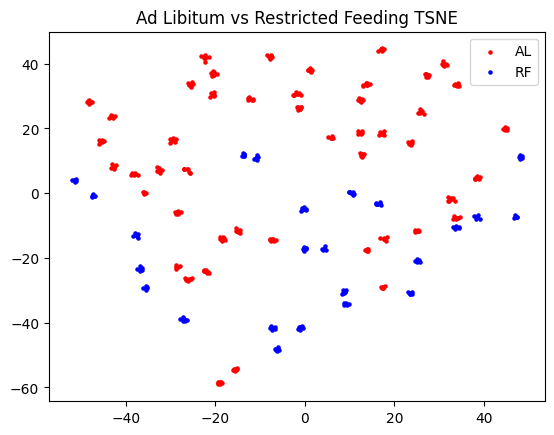

In [7]:
plt.clf()
tsne_reduction = TSNE(n_components=2, learning_rate='auto', init='random', perplexity=10).fit_transform(scaled_data).T
plt.scatter(tsne_reduction[0][WT_AL], tsne_reduction[1][WT_AL], color="red", s=5, label="AL")
plt.scatter(tsne_reduction[0][WT_RF], tsne_reduction[1][WT_RF], color="blue", s=5, label="RF")
plt.legend()
plt.title("Ad Libitum vs Restricted Feeding TSNE")

Text(0.5, 1.0, 'Ad Libitum vs Restricted Feeding UMAP')

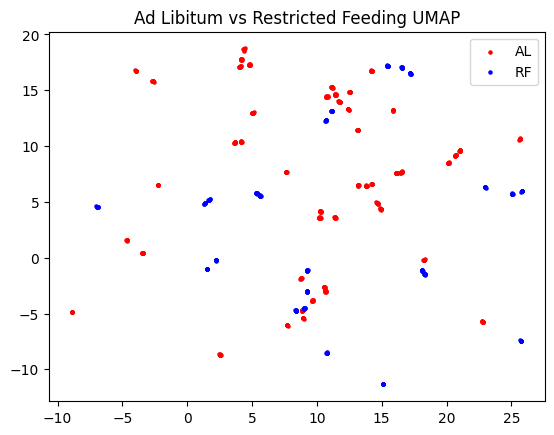

In [8]:
# Source: https://umap-learn.readthedocs.io/en/latest/basic_usage.html

reducer = umap.UMAP()
umap_reduction = reducer.fit_transform(scaled_data).T
plt.scatter(umap_reduction[0][WT_AL], umap_reduction[1][WT_AL], color="red", s=5, label="AL")
plt.scatter(umap_reduction[0][WT_RF], umap_reduction[1][WT_RF], color="blue", s=5, label="RF")
plt.legend()
plt.title("Ad Libitum vs Restricted Feeding UMAP")

In [9]:
# Creating dataframe with logfold change & p values
df_lf_p = {"GeneNames": [], "lfc": [], "p-value": [], 
           "AL-Expression": [], "RF-Expression": []}

# Calculate logfold change
for i in range(len(df)):
    expressions = list(df.iloc[i])[1:]
    gene = df.iloc[i]["Gene"]
    AL_expressions = np.array(expressions)[WT_AL]
    RF_expressions = np.array(expressions)[WT_RF]
    df_lf_p["GeneNames"].append(gene)
    df_lf_p["lfc"].append(np.mean(RF_expressions) - np.mean(AL_expressions))
    df_lf_p["p-value"].append(sp.stats.ttest_ind(RF_expressions, AL_expressions).pvalue)
    df_lf_p["AL-Expression"].append(np.mean(AL_expressions))
    df_lf_p["RF-Expression"].append(np.mean(RF_expressions))
    if i % 1000 == 0:
        print(i)

print("DONE PROCESSING")
# Adjust the p values
df_lf_p["p-value"] = sp.stats.false_discovery_control(df_lf_p["p-value"])

0
1000
2000
3000
4000
5000
6000
7000
8000
9000
10000
11000
12000
13000
14000
15000
16000
17000
18000
19000
20000
21000
22000
23000
24000
25000
26000
27000
28000
29000
30000
31000
32000
33000
34000
35000
36000
37000
DONE PROCESSING


Text(0.5, 1.0, 'Volcano Plot')

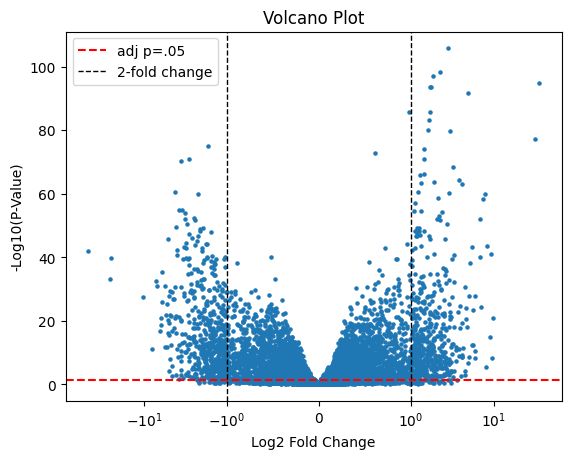

In [10]:
# The provided library crashed when trying to run it
# Source: https://python-fiddle.com/tutorials/matplotlib-volcano-plots
#plt.figure(figsize=(20, 4))
fig, ax = plt.subplots()
ax.set_xscale('symlog', linthresh=1.0)
plt.scatter(df_lf_p["lfc"], -np.log10(df_lf_p["p-value"]), s=5)
plt.axhline(-np.log10(0.05), color="red", linestyle="--", label="adj p=.05")
plt.axvline(-1, color="black", linestyle="--", linewidth=1, label="2-fold change")
plt.axvline(1, color="black", linestyle="--", linewidth=1)
plt.xlabel("Log2 Fold Change")
plt.ylabel("-Log10(P-Value)")
plt.legend()
plt.title("Volcano Plot")

In [151]:
# Source: https://www.biostars.org/p/9544260/
# We will cut off all insignificant p-values, then take top 50 logfold changes
df_vol = pd.DataFrame(df_lf_p)
df_vol.to_csv("results/step3_gene_significance.csv", index=False)
insignificant = df_vol[df_vol["p-value"] > .05].index
df_vol = df_vol.sort_values(by=["lfc"], ascending=False, key=abs)
df_vol_sorted = df_vol.drop(insignificant).sort_values(by=["lfc"], ascending=False, key=abs)[:50]
df_vol_sorted = df_vol_sorted.set_index(df_vol_sorted["GeneNames"])
df_vol_sorted[["lfc", "p-value"]].reset_index()

,GeneNames,lfc,p-value
0,Lars2,-47.318832,7.948135e-43
1,Grip2,35.362656,1.923222e-95
2,Gm26822,31.378184,4.465899e-78
3,Mir6236,-25.694386,7.921909e-34
4,AA474408,-25.186670,1.776517e-40
5,Gvin1,-10.166314,2.712755e-28
6,Cyp3a11,9.707480,1.538190e-21
7,Mup19,9.520621,7.252064e-09
8,mt-Nd5,9.316275,7.342064e-42
9,Bhmt,9.060270,9.350502e-16


In [12]:
# Pick 5 samples from each group randomly, then put on heatmap
AL_samples = np.array(random.sample(list(scaled_data[WT_AL]), 10))
RF_samples = np.array(random.sample(list(scaled_data[WT_RF]), 10))

samples_per_group = 10
gene_count = 20

top_genes = list(df_vol_sorted["GeneNames"][:gene_count])

In [13]:
gene_locations = []
for i in range(gene_count):
    gene_locations.append(df[df["Gene"] == top_genes[i]].iloc[0].name)

heatmap_df = {"Samples":[]}

for i in range(samples_per_group):
    heatmap_df["Samples"].append("AL Sample "+str(i+1))

for i in range(samples_per_group):
    heatmap_df["Samples"].append("RF Sample "+str(i+1))

print(gene_locations)
for i in range(gene_count):
    gl = gene_locations[i]
    heatmap_df[top_genes[i]] = []
    for j in range(10):
        heatmap_df[top_genes[i]].append(AL_samples[j][gl])
    for j in range(10):
        heatmap_df[top_genes[i]].append(RF_samples[j][gl])

df_heatmap = pd.DataFrame(heatmap_df)
df_heatmap = df_heatmap.set_index("Samples")
df_heatmap

[9907, 7612, 27072, 28075, 19655, 13421, 15813, 21263, 17476, 19970, 17472, 16219, 21270, 17466, 17467, 1660, 8722, 8068, 15911, 11393]


,Lars2,Grip2,Gm26822,Mir6236,AA474408,Gvin1,Cyp3a11,Mup19,mt-Nd5,Bhmt,mt-Nd4,Gstm1,Mup9,mt-Atp8,mt-Atp6,Cd5l,Apoa1,Oat,Cebpb,Abhd2
Samples,,,,,,,,,,,,,,,,,,,,
AL Sample 1,-0.726739,-1.152669,-1.481540,-0.523947,-0.222936,0.313596,-0.644037,-0.838657,-0.885713,-2.276635,-0.922821,-0.101965,-1.651481,-1.635668,-2.203102,2.047934,1.654506,-0.853463,-0.554650,0.062777
AL Sample 2,-0.607517,0.544719,0.512834,0.006088,-0.428458,-0.476704,0.218104,0.820206,0.747752,-0.914673,0.791874,-0.822201,0.579939,0.851081,1.240392,-0.821642,-0.425699,-0.265446,2.535599,-0.471998
AL Sample 3,-1.040500,-0.841703,-0.410447,-1.123870,-1.110580,0.711507,-0.464804,0.205524,-0.501623,0.939684,0.098249,-0.281995,0.479979,-0.160229,-0.283614,-0.111489,-0.127898,-1.099247,-1.197911,-0.826524
AL Sample 4,-0.465616,-0.697111,-0.067743,-0.453418,-0.490160,1.050036,-0.530603,0.611911,-0.925549,-0.074762,-0.708636,-0.776079,0.966926,-0.979277,-0.882625,0.731743,-0.127898,-0.322535,-0.266005,-0.894937
AL Sample 5,-0.166160,-0.826012,0.211528,-0.161576,-0.096044,2.246923,-0.155331,-2.401602,-0.611799,-0.886829,-0.749371,1.704717,-1.958968,-0.716226,-0.088733,1.748218,0.282912,-0.582808,-0.938314,2.140177
AL Sample 6,1.950273,-0.783451,-0.920403,1.709896,1.767244,0.123374,-1.072876,0.490609,-0.704148,0.599583,-0.558701,-0.712797,1.112911,-0.288037,-0.807234,0.676955,0.631485,0.070040,-1.033179,-0.423447
AL Sample 7,-0.528242,0.689665,0.945548,0.095170,0.078864,0.033989,0.502284,0.985738,1.966243,0.133171,1.722292,-0.776079,1.214708,1.772085,1.130933,-0.600830,-1.885234,0.263722,0.382326,-0.679451
AL Sample 8,-1.243498,-0.872263,-0.267079,-1.931950,-1.118882,0.121922,0.432855,-0.167787,-1.564287,-0.198875,-2.263391,-0.299672,-0.565360,-1.851949,-2.036235,1.272679,1.872150,0.070040,-0.241442,-0.959630
AL Sample 9,-0.077490,-0.458536,-0.435596,-0.253865,-0.205773,0.551003,-1.000509,-0.128015,-0.934688,0.020800,-1.173592,0.790590,-0.159312,-1.366152,-1.295079,0.927610,0.803021,-0.882674,-0.655310,-0.091862


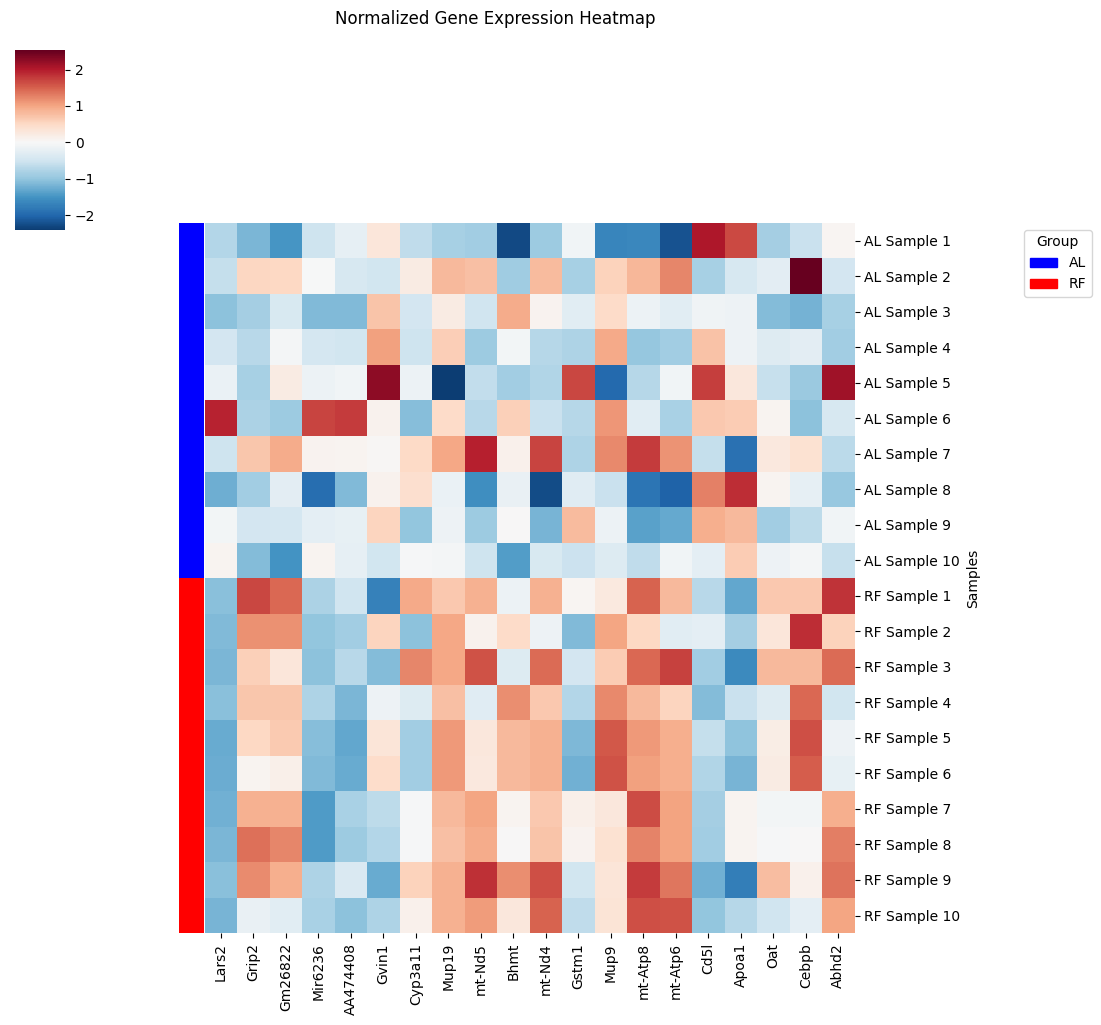

In [152]:
# Heatmap of 10 samples from each group

from matplotlib.patches import Patch
g = sns.clustermap(
    df_heatmap[top_genes],
    row_colors=["blue"]*samples_per_group+["red"]*samples_per_group,
    cmap="RdBu_r", center=0,
    row_cluster=False, col_cluster=False,
)

palette = {"AL": "blue", "RF": "red"}
handles = [Patch(color=c, label=grp) for grp, c in palette.items()]
g.ax_heatmap.legend(handles=handles, title="Group",
                    bbox_to_anchor=(1.25, 1), loc="upper left")
g.fig.suptitle("Normalized Gene Expression Heatmap", y=1.02)
plt.savefig('results/step4_heatmap.png')
plt.show()

In [112]:
# Method 1, Gene Ontology GProfiler
import re

# Puts the gene ontology name in the same format as all the other methods for easier comparison
def convert_go(go):
    go = re.sub(r'[^a-zA-Z0-9]+', '_', go)
    go = "GOBP_"+go.upper().strip("_")
    return go

gp = GProfiler(return_dataframe=True)
# Restrict to top 500 genes to focus on the biggest LFC
# We get 262 results
gpp_all = gp.profile(organism='mmusculus', query=list(df_vol["GeneNames"][:500]), sources=['GO:BP'], all_results=True)
gpp_all["name"] = gpp_all["name"].map(convert_go)
gpp = gpp_all[gpp_all['significant'] == True]
gpp.head(30)

,source,native,name,p_value,significant,description,term_size,query_size,intersection_size,effective_domain_size,precision,recall,query,parents
0,GO:BP,GO:0044281,GOBP_SMALL_MOLECULE_METABOLIC_PROCESS,2.134919e-55,True,"""The chemical reactions and pathways involving...",1549,443,137,24936,0.309255,0.088444,query_1,[GO:0008152]
1,GO:BP,GO:0019752,GOBP_CARBOXYLIC_ACID_METABOLIC_PROCESS,2.550917e-40,True,"""The chemical reactions and pathways involving...",769,443,86,24936,0.194131,0.111834,query_1,[GO:0043436]
2,GO:BP,GO:0043436,GOBP_OXOACID_METABOLIC_PROCESS,1.074272e-39,True,"""The chemical reactions and pathways involving...",783,443,86,24936,0.194131,0.109834,query_1,[GO:0006082]
3,GO:BP,GO:0006082,GOBP_ORGANIC_ACID_METABOLIC_PROCESS,1.970499e-39,True,"""The chemical reactions and pathways involving...",789,443,86,24936,0.194131,0.108999,query_1,[GO:0044281]
4,GO:BP,GO:0006629,GOBP_LIPID_METABOLIC_PROCESS,1.994072e-30,True,"""The chemical reactions and pathways involving...",1266,443,95,24936,0.214447,0.075039,query_1,[GO:0044238]
5,GO:BP,GO:0032787,GOBP_MONOCARBOXYLIC_ACID_METABOLIC_PROCESS,2.401819e-27,True,"""The chemical reactions and pathways involving...",549,443,61,24936,0.137698,0.111111,query_1,[GO:0019752]
6,GO:BP,GO:0044283,GOBP_SMALL_MOLECULE_BIOSYNTHETIC_PROCESS,7.490065e-27,True,"""The chemical reactions and pathways resulting...",500,443,58,24936,0.130926,0.116000,query_1,"[GO:0009058, GO:0044281]"
7,GO:BP,GO:0006631,GOBP_FATTY_ACID_METABOLIC_PROCESS,8.499860e-21,True,"""The chemical reactions and pathways involving...",357,443,44,24936,0.099323,0.123249,query_1,"[GO:0006629, GO:0032787]"
8,GO:BP,GO:0046394,GOBP_CARBOXYLIC_ACID_BIOSYNTHETIC_PROCESS,4.424731e-19,True,"""The chemical reactions and pathways resulting...",247,443,36,24936,0.081264,0.145749,query_1,"[GO:0016053, GO:0019752]"
9,GO:BP,GO:0016053,GOBP_ORGANIC_ACID_BIOSYNTHETIC_PROCESS,7.737101e-19,True,"""The chemical reactions and pathways resulting...",251,443,36,24936,0.081264,0.143426,query_1,"[GO:0006082, GO:0044283]"


In [16]:
# Grab mouse gene ontology data
from gseapy import Msigdb

msig = Msigdb()
go_bp = msig.get_gmt(category="m5.go.bp", dbver="2023.1.Mm") # Mouse Gene Ontology Biological Process

In [113]:
# Method 2, Wilcoxon Rank Sum
all_genes = set(df["Gene"])
rank_sums = []
gos = []

# Calculate ranked sum for each GO
for go, genes in go_bp.items():
    inter = set(genes) & all_genes
    if len(inter) < 10 or len(inter) > 500:
        continue # Too few/many genes
    all_other_genes = all_genes - inter
    inter = list(inter)
    # Wilcoxin needs to compare lfc of all genes
    # in this ontology vs all other genes not in it
    all_other_lfcs = list(df_vol[~df_vol["GeneNames"].isin(genes)]["lfc"])
    lfcs = list(df_vol[df_vol["GeneNames"].isin(genes)]["lfc"])
    pv = sp.stats.ranksums(lfcs, all_other_lfcs).pvalue
    rank_sums.append(pv)
    gos.append(go)

# Adjust p values
rank_sums = sp.stats.false_discovery_control(rank_sums)

sig_gos = []
sig_gos_all = []
for i in range(len(rank_sums)):
    if rank_sums[i] < .05:
        sig_gos.append((gos[i], rank_sums[i]))
    sig_gos_all.append((gos[i], rank_sums[i]))

sig_gos.sort(key=lambda x: x[1])
print("Calculated significant ontologies.")

Calculated significant ontologies.


In [114]:
wilcoxin_results = pd.DataFrame(dict(sig_gos), index = ["P-Value"]).T
wilcoxin_results_all = pd.DataFrame(dict(sig_gos_all), index = ["P-Value"]).T
wilcoxin_results.index.name = "Gene Ontology: Biological Process"
wilcoxin_results_all.index.name = "Gene Ontology: Biological Process"
wilcoxin_results = wilcoxin_results.reset_index()
wilcoxin_results_all = wilcoxin_results.reset_index()
wilcoxin_results.head(10)

,Gene Ontology: Biological Process,P-Value
0,GOBP_ADAPTIVE_IMMUNE_RESPONSE,3.099743e-38
1,GOBP_ACTIVATION_OF_IMMUNE_RESPONSE,9.047866e-38
2,GOBP_LEUKOCYTE_MEDIATED_IMMUNITY,1.724704e-32
3,GOBP_REGULATION_OF_IMMUNE_EFFECTOR_PROCESS,7.560134e-28
4,GOBP_IMMUNE_RESPONSE_REGULATING_SIGNALING_PATHWAY,8.396593e-28
5,GOBP_ADAPTIVE_IMMUNE_RESPONSE_BASED_ON_SOMATIC...,2.583382e-27
6,GOBP_RESPONSE_TO_VIRUS,1.412665e-26
7,GOBP_LEUKOCYTE_MIGRATION,5.550596e-26
8,GOBP_POSITIVE_REGULATION_OF_DEFENSE_RESPONSE,5.432418e-25
9,GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY,6.989364e-25


In [19]:
# Method 3, PyDESeq2

# We need to work with unnormalized data because that's all that PyDESeq2 works with.
df_unnormalized = pd.read_csv("Data/SRP064298/unnormalized.tsv",sep='\t').drop_duplicates(subset='Gene').set_index("Gene").T
# We need to feed PyDESeq2 integers & only the two conditions
df_unnormalized = pd.concat([df_unnormalized[WT_RF], df_unnormalized[WT_AL]]).round().astype(int)

# Here we make a dataframe of the conditions of each sample.
conditions = df_unnormalized.index.to_frame()
conditions.iloc[:sum(WT_RF), :] = "RF"
conditions.iloc[sum(WT_RF):, :] = "AL"
conditions.columns = ["condition"]

In [21]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

# Run the pydeseq2 analysis
inference = DefaultInference(n_cpus=16)

dds = DeseqDataSet(
    counts=df_unnormalized,
    metadata=conditions,
    design="~condition",
    inference=inference,
)
dds.deseq2()

ds = DeseqStats(dds, contrast=["condition", "RF", "AL"], inference=inference)
ds.summary()
res = ds.results_df
res = res.dropna(subset=["stat"])

Fitting size factors...


Using None as control genes, passed at DeseqDataSet initialization


... done in 1.02 seconds.

Fitting dispersions...
... done in 2.29 seconds.

Fitting dispersion trend curve...
... done in 0.69 seconds.

Fitting MAP dispersions...
... done in 3.74 seconds.

Fitting LFCs...
... done in 1.98 seconds.

Calculating cook's distance...
... done in 0.80 seconds.

Replacing 49 outlier genes.

Fitting dispersions...
... done in 0.02 seconds.

Fitting MAP dispersions...
... done in 0.02 seconds.

Fitting LFCs...
... done in 0.02 seconds.

Running Wald tests...
... done in 1.70 seconds.



Log2 fold change & Wald test p-value: condition RF vs AL
                 baseMean  log2FoldChange     lfcSE      stat        pvalue  \
Gene                                                                          
Gnai3          417.293995        0.126282  0.013049  9.677387  3.762083e-22   
Pbsn             0.000000             NaN       NaN       NaN           NaN   
Cdc45            6.087828       -0.318870  0.077405 -4.119520  3.796631e-05   
H19              0.591181       -0.032683  0.222711 -0.146752  8.833275e-01   
Scml2            0.247322       -0.270021  0.411890 -0.655566  5.121035e-01   
...                   ...             ...       ...       ...           ...   
Gm50415          0.000000             NaN       NaN       NaN           NaN   
Vmn1r64          0.000000             NaN       NaN       NaN           NaN   
Gm50102          1.339494       -0.130057  0.121928 -1.066667  2.861222e-01   
Gm19519          0.052550        0.011784  1.046170  0.011264  9.910125e-0

In [25]:
import gseapy as gp

# here we run the enrichment analysis using gp

rnk = res["stat"].sort_values(ascending=False).to_frame()
pre_res = gp.prerank(rnk=rnk, gene_sets=go_bp, min_size=15, max_size=500, permutation_num=1000, threads=16)
pre_res.res2d

2026-09-25 03:21:41,728 [WARNING] Duplicated values found in preranked stats: 8.60% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,GOBP_CELLULAR_RESPONSE_TO_INTERFERON_BETA,-0.843865,-2.350298,0.000000,0.000000,0.0,38/58,7.84%,Gbp2b;Tgtp1;Ifit3;9930111J21Rik1;Igtp;Oas1a;Gb...
1,prerank,GOBP_RESPONSE_TO_INTERFERON_BETA,-0.808713,-2.328012,0.000000,0.000000,0.0,43/70,7.84%,Gbp2b;Tgtp1;Ifit3;9930111J21Rik1;Igtp;Oas1a;Gb...
2,prerank,GOBP_POSITIVE_REGULATION_OF_PHAGOCYTOSIS,-0.757912,-2.287987,0.000000,0.000000,0.0,56/87,11.34%,Sod1;Apoa1;Cfb;Colec10;Fcer1g;Cfp;Fcgr3;Dock2;...
3,prerank,GOBP_PHAGOCYTOSIS,-0.669820,-2.275021,0.000000,0.000000,0.0,118/231,11.51%,Sod1;Apoa1;Pld4;Cfb;Tyrobp;Colec10;Fcer1g;Cfp;...
4,prerank,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PE...,-0.785117,-2.263803,0.000000,0.000000,0.0,35/70,7.40%,H2-Q7;H2-Q4;H2-Q6;Ctss;H2-T22;H2-D1;Cd74;H2-T2...
...,...,...,...,...,...,...,...,...,...,...
4293,prerank,GOBP_NEUROMUSCULAR_SYNAPTIC_TRANSMISSION,-0.231388,-0.565880,0.997921,0.996356,1.0,11/32,28.66%,Rimbp2;Erc2;Etv5;Stxbp1;Egr3;Fchsd1;Chrnb1;Nrx...
4294,prerank,GOBP_GASTRIC_ACID_SECRETION,0.255160,0.558817,0.987879,0.997867,1.0,4/18,18.67%,Tff2;Hip1r;Snx10;Cckar
4295,prerank,GOBP_RESPONSE_TO_PAIN,0.207578,0.550164,1.000000,0.997830,1.0,12/44,24.26%,Ntrk1;Gch1;Adam11;Aqp9;Tacr1;Thbs1;Vwa1;Git2;G...
4296,prerank,GOBP_PIRNA_PROCESSING,0.234204,0.530623,0.997942,0.998229,1.0,3/19,24.80%,Pnldc1;Btbd18;Asz1


In [115]:
gp_table = pre_res.res2d[pre_res.res2d["FDR q-val"] < .05]
gp_table_all = pre_res.res2d
gp_table.head(20)

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,GOBP_CELLULAR_RESPONSE_TO_INTERFERON_BETA,-0.843865,-2.350298,0.0,0.0,0.0,38/58,7.84%,Gbp2b;Tgtp1;Ifit3;9930111J21Rik1;Igtp;Oas1a;Gb...
1,prerank,GOBP_RESPONSE_TO_INTERFERON_BETA,-0.808713,-2.328012,0.0,0.0,0.0,43/70,7.84%,Gbp2b;Tgtp1;Ifit3;9930111J21Rik1;Igtp;Oas1a;Gb...
2,prerank,GOBP_POSITIVE_REGULATION_OF_PHAGOCYTOSIS,-0.757912,-2.287987,0.0,0.0,0.0,56/87,11.34%,Sod1;Apoa1;Cfb;Colec10;Fcer1g;Cfp;Fcgr3;Dock2;...
3,prerank,GOBP_PHAGOCYTOSIS,-0.669820,-2.275021,0.0,0.0,0.0,118/231,11.51%,Sod1;Apoa1;Pld4;Cfb;Tyrobp;Colec10;Fcer1g;Cfp;...
4,prerank,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PE...,-0.785117,-2.263803,0.0,0.0,0.0,35/70,7.40%,H2-Q7;H2-Q4;H2-Q6;Ctss;H2-T22;H2-D1;Cd74;H2-T2...
5,prerank,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION,-0.724711,-2.254533,0.0,0.0,0.0,66/117,11.99%,H2-Q7;H2-Q4;Psmb8;H2-Q6;Ctss;H2-T22;Cd68;H2-D1...
6,prerank,GOBP_HUMORAL_IMMUNE_RESPONSE_MEDIATED_BY_CIRCU...,-0.805244,-2.252658,0.0,0.0,0.0,31/52,10.59%,C1ra;C1qb;C1qa;C1s1;C1qc;Ighg2c;Ighm;Igha;Cd81...
7,prerank,GOBP_POSITIVE_REGULATION_OF_CHEMOKINE_PRODUCTION,-0.758020,-2.234788,0.0,0.0,0.0,38/82,11.48%,Csf1r;Cd74;Oas1a;Oas3;Oas1g;Aif1;App;Mif;Syk;I...
8,prerank,GOBP_HUMORAL_IMMUNE_RESPONSE,-0.661172,-2.230771,0.0,0.0,0.0,76/218,9.72%,C1ra;Vsig4;F2;Cd5l;Rpl30;C1qb;C1qa;C1s1;Cfb;C1...
9,prerank,GOBP_ADAPTIVE_IMMUNE_RESPONSE,-0.624662,-2.228679,0.0,0.0,0.0,217/482,15.07%,H2-Q7;C1ra;H2-Q4;H2-Q6;Irf7;Clec4g;Ctsh;C1qb;H...


In [144]:
# 6: Combine all results into one table (csv file) for each term.

gpp_all
gp_table_all
wilcoxin_results_all

combined_results = {}

# Count terms found
for go in list(gpp_all["name"]) + list(gp_table_all["Term"]) + list(wilcoxin_results_all["Gene Ontology: Biological Process"]):
    if go not in combined_results:
        combined_results[go] = [0, 0, "", "", ""]
    combined_results[go][0] += 1

# Count terms significant
for go in list(gpp["name"]) + list(gp_table["Term"]) + list(wilcoxin_results["Gene Ontology: Biological Process"]):
    combined_results[go][1] += 1

# Add p values
for i in range(len(gpp_all)):
    go = gpp_all.iloc[i]
    combined_results[go["name"]][2] = go["p_value"]

for i in range(len(wilcoxin_results_all)):
    go = wilcoxin_results_all.iloc[i]
    combined_results[go["Gene Ontology: Biological Process"]][3] = go["P-Value"]

for i in range(len(gp_table_all)):
    go = gp_table_all.iloc[i]
    combined_results[go["Term"]][4] = go["FDR q-val"]


combined_df = pd.DataFrame.from_dict(combined_results, orient="index", columns=["Methods Found", "Methods Significant", "GProfiler p-value", "Wilcoxon p-value", "PyDESeq2 q-value"])
combined_df = combined_df[combined_df["Methods Significant"] >= 1]
combined_df.to_csv("results/step6_joint_table.csv", index_label="GO Term")
combined_df

,Methods Found,Methods Significant,GProfiler p-value,Wilcoxon p-value,PyDESeq2 q-value
GOBP_SMALL_MOLECULE_METABOLIC_PROCESS,1,1,0.0,,
GOBP_CARBOXYLIC_ACID_METABOLIC_PROCESS,1,1,0.0,,
GOBP_OXOACID_METABOLIC_PROCESS,1,1,0.0,,
GOBP_ORGANIC_ACID_METABOLIC_PROCESS,1,1,0.0,,
GOBP_LIPID_METABOLIC_PROCESS,1,1,0.0,,
...,...,...,...,...,...
GOBP_BRANCHING_MORPHOGENESIS_OF_A_NERVE,1,1,,0.045818,
GOBP_MEIOSIS_II_CELL_CYCLE_PROCESS,1,1,,0.047144,
GOBP_EPITHELIAL_CELL_PROLIFERATION_INVOLVED_IN_LUNG_MORPHOGENESIS,1,1,,0.049274,
GOBP_UREA_TRANSPORT,1,1,,0.049586,


In [78]:
shared_top = set(gp_table["Term"]) & set(wilcoxin_results["Gene Ontology: Biological Process"]) & set(gpp["name"])
gp_table[gp_table["Term"].isin(shared_top)]

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
4,prerank,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PE...,-0.785117,-2.263803,0.0,0.000000,0.000,35/70,7.40%,H2-Q7;H2-Q4;H2-Q6;Ctss;H2-T22;H2-D1;Cd74;H2-T2...
5,prerank,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION,-0.724711,-2.254533,0.0,0.000000,0.000,66/117,11.99%,H2-Q7;H2-Q4;Psmb8;H2-Q6;Ctss;H2-T22;Cd68;H2-D1...
6,prerank,GOBP_HUMORAL_IMMUNE_RESPONSE_MEDIATED_BY_CIRCU...,-0.805244,-2.252658,0.0,0.000000,0.000,31/52,10.59%,C1ra;C1qb;C1qa;C1s1;C1qc;Ighg2c;Ighm;Igha;Cd81...
8,prerank,GOBP_HUMORAL_IMMUNE_RESPONSE,-0.661172,-2.230771,0.0,0.000000,0.000,76/218,9.72%,C1ra;Vsig4;F2;Cd5l;Rpl30;C1qb;C1qa;C1s1;Cfb;C1...
9,prerank,GOBP_ADAPTIVE_IMMUNE_RESPONSE,-0.624662,-2.228679,0.0,0.000000,0.000,217/482,15.07%,H2-Q7;C1ra;H2-Q4;H2-Q6;Irf7;Clec4g;Ctsh;C1qb;H...
11,prerank,GOBP_LEUKOCYTE_MEDIATED_IMMUNITY,-0.629733,-2.223777,0.0,0.000000,0.000,173/435,10.59%,H2-Q7;C1ra;H2-Q4;H2-Q6;Irf7;F2;Clec4g;Ctsh;C1q...
12,prerank,GOBP_B_CELL_MEDIATED_IMMUNITY,-0.683053,-2.223131,0.0,0.000000,0.000,77/159,11.99%,C1ra;Irf7;C1qb;C1qa;Cd74;C1s1;H2-Ab1;C1qc;H2-A...
15,prerank,GOBP_ADAPTIVE_IMMUNE_RESPONSE_BASED_ON_SOMATIC...,-0.631138,-2.197030,0.0,0.000000,0.000,164/347,15.07%,H2-Q7;C1ra;H2-Q4;H2-Q6;Irf7;Clec4g;Ctsh;C1qb;H...
17,prerank,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_EX...,-0.862523,-2.174872,0.0,0.000000,0.000,24/34,7.40%,Ctss;Cd74;H2-Ab1;H2-Aa;Fcer1g;Fcgr3;H2-Eb1;H2-...
18,prerank,GOBP_ACTIVATION_OF_IMMUNE_RESPONSE,-0.607988,-2.173971,0.0,0.000000,0.000,217/467,12.52%,C1ra;Rps3;Vsig4;Irf7;Cd5l;C1qb;C1qa;Trim30d;C1...


In [79]:
wilcoxin_results[wilcoxin_results["Gene Ontology: Biological Process"].isin(shared_top)]

,Gene Ontology: Biological Process,P-Value
0,GOBP_ADAPTIVE_IMMUNE_RESPONSE,3.099743e-38
1,GOBP_ACTIVATION_OF_IMMUNE_RESPONSE,9.047866e-38
2,GOBP_LEUKOCYTE_MEDIATED_IMMUNITY,1.724704e-32
3,GOBP_REGULATION_OF_IMMUNE_EFFECTOR_PROCESS,7.560134e-28
5,GOBP_ADAPTIVE_IMMUNE_RESPONSE_BASED_ON_SOMATIC...,2.583382e-27
9,GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY,6.989364e-25
11,GOBP_DEFENSE_RESPONSE_TO_SYMBIONT,1.152151e-23
16,GOBP_RESPONSE_TO_TYPE_II_INTERFERON,1.929918e-21
19,GOBP_LEUKOCYTE_PROLIFERATION,4.365277e-20
26,GOBP_CELLULAR_RESPONSE_TO_TYPE_II_INTERFERON,3.368953e-18


In [80]:
gpp[gpp["name"].isin(shared_top)]

,source,native,name,p_value,significant,description,term_size,query_size,intersection_size,effective_domain_size,precision,recall,query,parents
21,GO:BP,GO:0006956,GOBP_COMPLEMENT_ACTIVATION,1.130861e-14,True,"""Any process involved in the activation of any...",49,443,17,24936,0.038375,0.346939,query_1,"[GO:0002252, GO:0002253, GO:0006959]"
22,GO:BP,GO:0002455,GOBP_HUMORAL_IMMUNE_RESPONSE_MEDIATED_BY_CIRCU...,2.922669e-14,True,"""An immune response dependent upon secreted im...",43,443,16,24936,0.036117,0.372093,query_1,"[GO:0006959, GO:0016064]"
23,GO:BP,GO:0006958,GOBP_COMPLEMENT_ACTIVATION_CLASSICAL_PATHWAY,3.517418e-14,True,"""Any process involved in the activation of any...",29,443,14,24936,0.031603,0.482759,query_1,"[GO:0002455, GO:0006956]"
31,GO:BP,GO:0002449,GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY,4.772164e-13,True,"""Any process involved in the carrying out of a...",271,443,31,24936,0.069977,0.114391,query_1,[GO:0002443]
34,GO:BP,GO:0048002,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PE...,1.390722e-12,True,"""The process in which an antigen-presenting ce...",53,443,16,24936,0.036117,0.301887,query_1,[GO:0019882]
38,GO:BP,GO:0019724,GOBP_B_CELL_MEDIATED_IMMUNITY,3.118008e-11,True,"""Any process involved with the carrying out of...",129,443,21,24936,0.047404,0.162791,query_1,"[GO:0002449, GO:0002460]"
39,GO:BP,GO:0002443,GOBP_LEUKOCYTE_MEDIATED_IMMUNITY,3.442038e-11,True,"""Any process involved in the carrying out of a...",360,443,33,24936,0.074492,0.091667,query_1,[GO:0002252]
43,GO:BP,GO:0006959,GOBP_HUMORAL_IMMUNE_RESPONSE,6.835705e-11,True,"""An immune response mediated through a body fl...",134,443,21,24936,0.047404,0.156716,query_1,[GO:0006955]
45,GO:BP,GO:0002460,GOBP_ADAPTIVE_IMMUNE_RESPONSE_BASED_ON_SOMATIC...,1.684421e-10,True,"""An immune response mediated by lymphocytes ex...",291,443,29,24936,0.065463,0.099656,query_1,[GO:0002250]
47,GO:BP,GO:0019882,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION,1.923005e-10,True,"""The process in which an antigen-presenting ce...",96,443,18,24936,0.040632,0.187500,query_1,[GO:0002376]


In [90]:
top_10 = (
    gpp.merge(wilcoxin_results, left_on="name", right_on="Gene Ontology: Biological Process", how="inner")
    .merge(gp_table, left_on="name", right_on="Term", how="inner")
    .drop(columns=["name", "Term"])
)[:10]

top_10 = top_10[["Gene Ontology: Biological Process", "p_value", "P-Value", "FDR q-val"]]
top_10["Methods Significant"] = [3] * 10
top_10.columns = ["GO","GProfiler p-value","Wilcoxin p-value","PyDESeq2 q-value","Methods Significant"]
top_10

,GO,GProfiler p-value,Wilcoxin p-value,PyDESeq2 q-value,Methods Significant
0,GOBP_COMPLEMENT_ACTIVATION,1.130861e-14,4.477831e-10,0.000000,3
1,GOBP_HUMORAL_IMMUNE_RESPONSE_MEDIATED_BY_CIRCU...,2.922669e-14,6.535668e-13,0.000000,3
2,GOBP_COMPLEMENT_ACTIVATION_CLASSICAL_PATHWAY,3.517418e-14,1.113622e-07,0.000024,3
3,GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY,4.772164e-13,6.989364e-25,0.000000,3
4,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PE...,1.390722e-12,6.769984e-10,0.000000,3
5,GOBP_B_CELL_MEDIATED_IMMUNITY,3.118008e-11,3.092034e-17,0.000000,3
6,GOBP_LEUKOCYTE_MEDIATED_IMMUNITY,3.442038e-11,1.724704e-32,0.000000,3
7,GOBP_HUMORAL_IMMUNE_RESPONSE,6.835705e-11,1.030373e-10,0.000000,3
8,GOBP_ADAPTIVE_IMMUNE_RESPONSE_BASED_ON_SOMATIC...,1.684421e-10,2.583382e-27,0.000000,3
9,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION,1.923005e-10,1.525017e-17,0.000000,3
